In [3]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Set working directory to the persistent project folder
project_path = '/content/drive/MyDrive/GROUP21_CENG313'
os.chdir(project_path)
!cp /content/drive/MyDrive/GROUP21_CENG313/data/birdclef-2025.zip /content
!unzip -q /content/birdclef-2025.zip -d /content/data
!rm /content/birdclef-2025.zip
%cd /content
!du -sh data

Mounted at /content/drive


## 2. Data Quality and Preprocessing
Real world data is usually (noisy), (incomplete)   (inconsistent). We first have to check the structural integrity and reliability of the dataset. Therefore we are performing a quality check to the dataset.

In [14]:
import pandas as pd
import numpy as np
import librosa
import os
from tqdm import tqdm

# Define paths
data_dir = 'data'
metadata_path = os.path.join(data_dir, 'train.csv')
audio_dir = os.path.join(data_dir, 'train_audio')

# Load metadata
df = pd.read_csv(metadata_path)

# 1. Check for Missing Values (Incomplete Data)
print("--- Missing Values ---")
missing_data = df.isnull().sum()
print(missing_data[missing_data > 0])
print("\n")

# 2. Extract Audio Properties (Extremes, Noise, Inconsistencies)
# To save time in the initial run, we analyze a random sample of 500 rows.
sample_df = df.sample(n=500, random_state=42).copy()
durations = []
sample_rates = []
corrupted_files = []

print("--- Analyzing Audio Files for Quality ---")
for idx, row in tqdm(sample_df.iterrows(), total=len(sample_df)):
    file_path = os.path.join(audio_dir, row['filename'])
    try:
        # Load audio using librosa to check native properties without resampling
        y, sr = librosa.load(file_path, sr=None)
        durations.append(librosa.get_duration(y=y, sr=sr))
        sample_rates.append(sr)
    except Exception as e:
        corrupted_files.append(row['filename'])
        durations.append(np.nan)
        sample_rates.append(np.nan)

sample_df['duration'] = durations
sample_df['native_sr'] = sample_rates

# 3. Analyze Extremes and Inconsistencies
print("\n--- Audio Durations (Extremes) ---")
print(sample_df['duration'].describe())

print("\n--- Sample Rates (Inconsistencies) ---")
print(sample_df['native_sr'].value_counts())

print("\n--- Corrupted Files (Noise) ---")
print(f"Total corrupted/unreadable files: {len(corrupted_files)}")
if len(corrupted_files) > 0:
    print(corrupted_files)

--- Missing Values ---
latitude     809
longitude    809
dtype: int64


--- Analyzing Audio Files for Quality ---


100%|██████████| 500/500 [00:27<00:00, 17.97it/s]


--- Audio Durations (Extremes) ---
count    500.000000
mean      34.974268
std       44.707344
min        0.878750
25%       10.550125
50%       20.663000
75%       41.455500
max      443.036750
Name: duration, dtype: float64

--- Sample Rates (Inconsistencies) ---
native_sr
32000    500
Name: count, dtype: int64

--- Corrupted Files (Noise) ---
Total corrupted/unreadable files: 0


- **Missing Values:** Some of the data has the lack for `latitude` and `longitude` labels . This fetures will not be used by the model so they, as a column, will be dropped from the set instead of imputation.



Total number of samples: 28564
Total number of unique species: 206


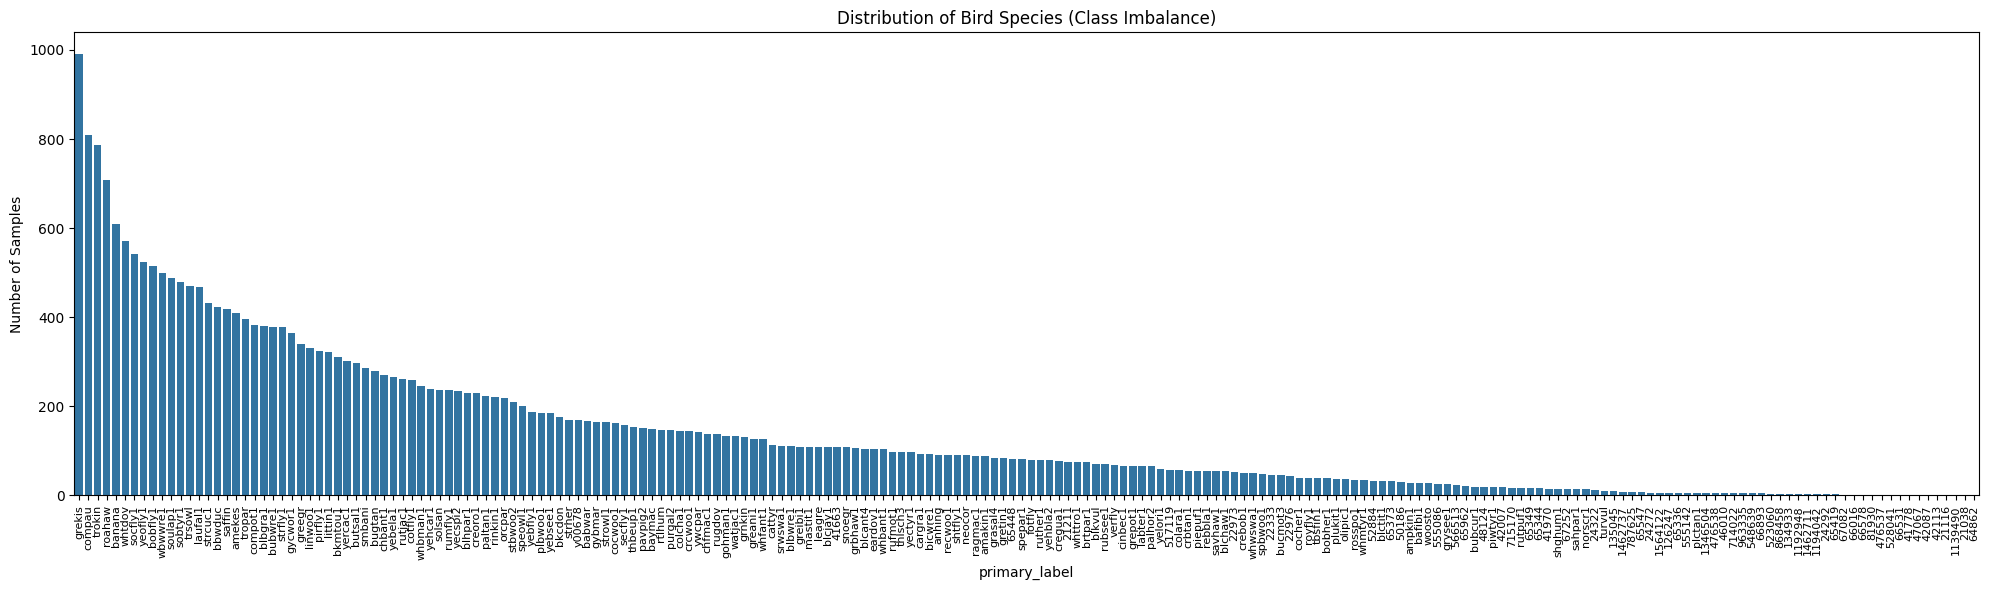

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Define file paths
data_dir = '/content/data'
metadata_path = os.path.join(data_dir, 'train.csv')

# Load and inspect metadata
df = pd.read_csv(metadata_path)
print(f"Total number of samples: {len(df)}")
print(f"Total number of unique species: {df['primary_label'].nunique()}")

# Plot class distribution
plt.figure(figsize=(20, 6))
sns.countplot(data=df, x='primary_label', order=df['primary_label'].value_counts().index)
plt.xticks(rotation=90, fontsize=8)
plt.title('Distribution of Bird Species (Class Imbalance)')
plt.ylabel('Number of Samples')
plt.tight_layout()
plt.show()

Measuring exact durations for all files using soundfile...


100%|██████████| 28564/28564 [01:27<00:00, 324.95it/s]


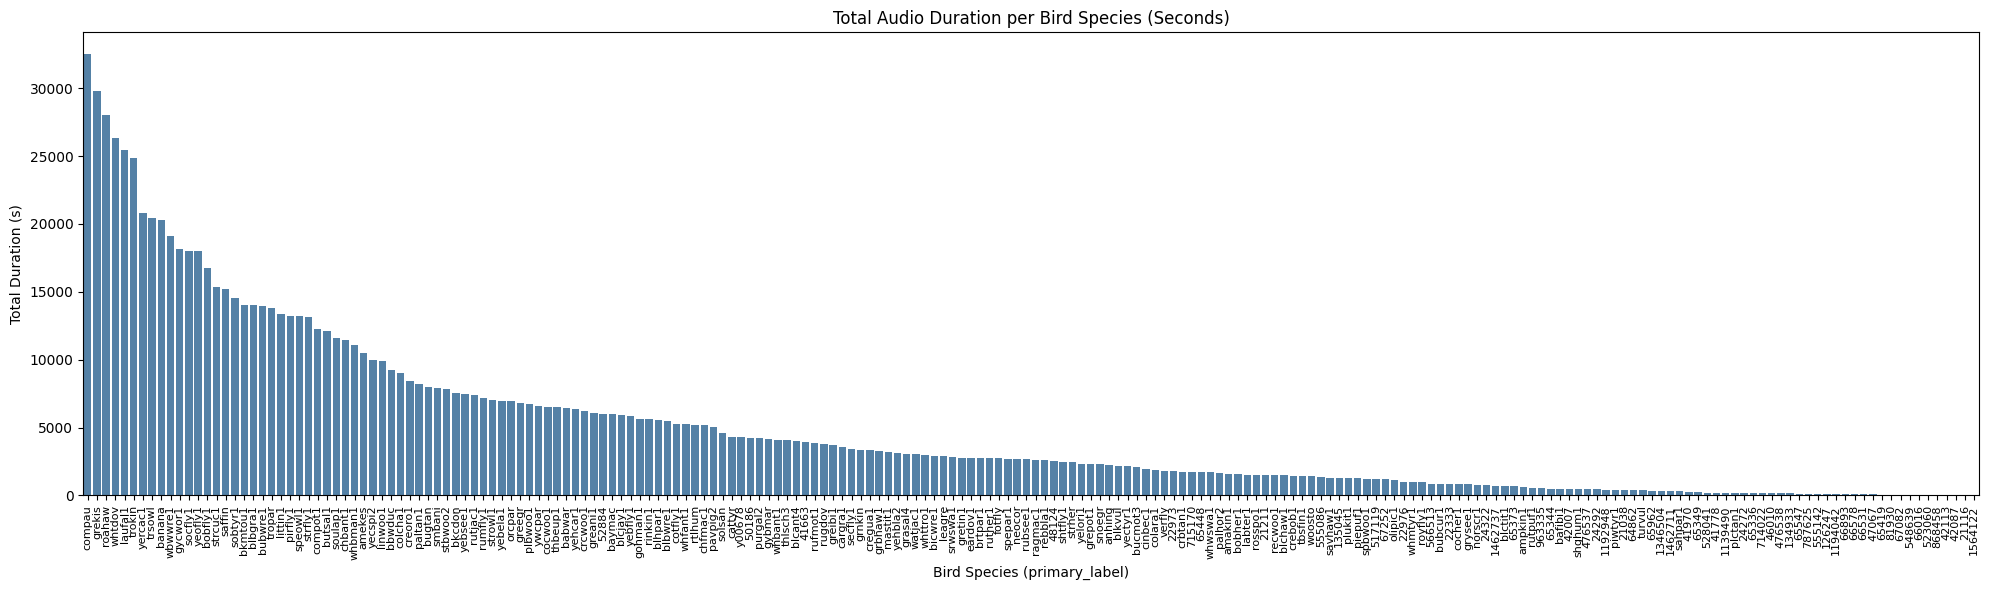


Top 5 species by total audio duration (seconds):
primary_label
compau     32493.263125
grekis     29803.540500
roahaw     28062.403344
whtdov     26327.295375
laufal1    25430.508656
Name: exact_duration, dtype: float64

Bottom 5 species by total audio duration (seconds):
primary_label
868458     23.560219
42113      22.652406
42087      21.132094
21116      13.055500
1564122    11.330063
Name: exact_duration, dtype: float64


In [23]:
import soundfile as sf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from tqdm import tqdm

local_audio_dir = '/content/data/train_audio'
durations = []

print("Measuring exact durations for all files using soundfile...")
for idx, row in tqdm(df.iterrows(), total=len(df)):
    file_path = os.path.join(local_audio_dir, row['filename'])
    try:
        # Fetch audio metadata directly from the header using soundfile
        info = sf.info(file_path)
        durations.append(info.duration)
    except Exception as e:
        print(f"Error reading {row['filename']}: {e}")
        durations.append(0.0)

df['exact_duration'] = durations

# Group by class and sum the durations
duration_per_class = df.groupby('primary_label')['exact_duration'].sum().sort_values(ascending=False)

# Plotting the total duration per class
plt.figure(figsize=(20, 6))
sns.barplot(x=duration_per_class.index, y=duration_per_class.values, color='steelblue')
plt.xticks(rotation=90, fontsize=8)
plt.title('Total Audio Duration per Bird Species (Seconds)')
plt.ylabel('Total Duration (s)')
plt.xlabel('Bird Species (primary_label)')
plt.tight_layout()
plt.show()

# Display the most and least represented classes by duration
print("\nTop 5 species by total audio duration (seconds):")
print(duration_per_class.head(5))
print("\nBottom 5 species by total audio duration (seconds):")
print(duration_per_class.tail(5))

/tmp/ipykernel_6654/1911334164.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='rating', palette='viridis')


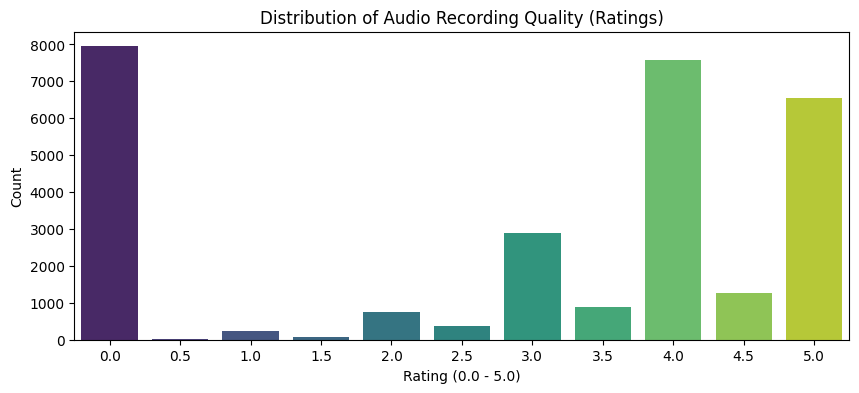

/tmp/ipykernel_6654/1911334164.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_authors.values, y=top_authors.index, palette='magma')


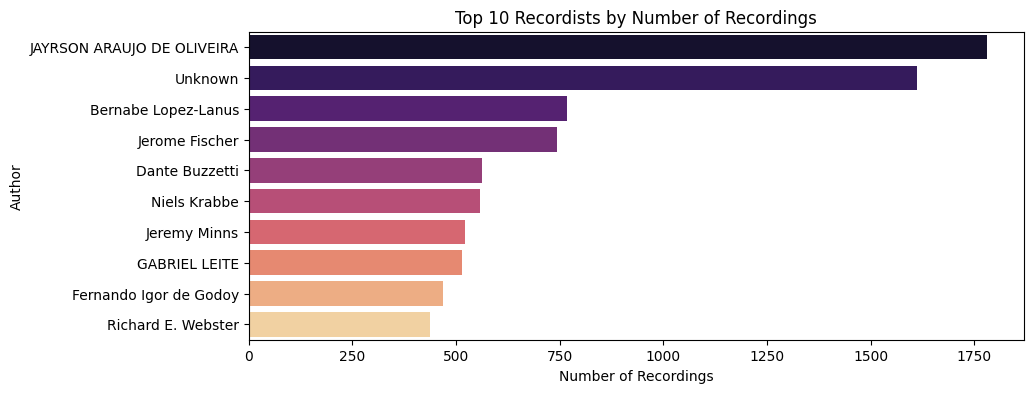


--- Sample Audio Details ---
Species: amekes
Author: Jacob Malcom
Rating: 0.0
File: amekes/iNat5018.ogg


In [20]:
import IPython.display as ipd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Rating (Kayıt Kalitesi) Dağılımı
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x='rating', palette='viridis')
plt.title('Distribution of Audio Recording Quality (Ratings)')
plt.xlabel('Rating (0.0 - 5.0)')
plt.ylabel('Count')
plt.show()

# 2. Recordist (Kayıt Yapan Kişi) Dağılımı - Top 10
plt.figure(figsize=(10, 4))
top_authors = df['author'].value_counts().head(10)
sns.barplot(x=top_authors.values, y=top_authors.index, palette='magma')
plt.title('Top 10 Recordists by Number of Recordings')
plt.xlabel('Number of Recordings')
plt.ylabel('Author')
plt.show()

# 3. Rastgele Bir Sesi Dinleme
sample = df.sample(1).iloc[0]
sample_path = f"/content/data/train_audio/{sample['filename']}"

print(f"\n--- Sample Audio Details ---")
print(f"Species: {sample['primary_label']}")
print(f"Author: {sample['author']}")
print(f"Rating: {sample['rating']}")
print(f"File: {sample['filename']}")

# Sesi notebook üzerinde oynat
display(ipd.Audio(sample_path))

Plotting spectrogram for species: 1139490


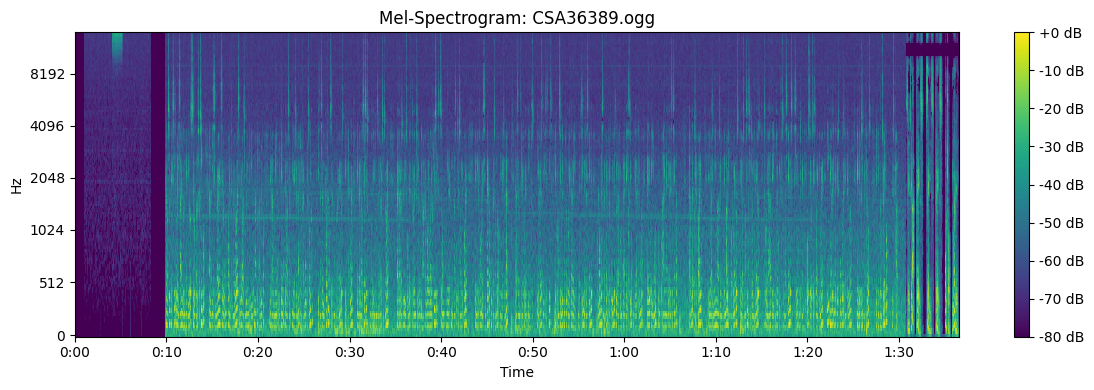

In [17]:
import os
from drive.MyDrive.GROUP21_CENG313.src.data import plot_mel_spectrogram

# Get a sample audio file path from the dataframe
sample_row = df.iloc[1]
sample_audio_path = os.path.join(data_dir, 'train_audio', sample_row['filename'])

# Call the function from src/data.py
print(f"Plotting spectrogram for species: {sample_row['primary_label']}")
plot_mel_spectrogram(sample_audio_path)

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# Assume 'df' is the metadata dataframe loaded in the previous steps
encoder = LabelEncoder()
df['label_id'] = encoder.fit_transform(df['primary_label'])
num_classes = len(encoder.classes_)

# Stratified split to maintain class distribution in the validation set
train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df['label_id']
)

print(f"Total classes: {num_classes}")
print(f"Training samples: {len(train_df)}")
print(f"Validation samples: {len(val_df)}")

Total classes: 206
Training samples: 22851
Validation samples: 5713


Using device: cpu
Error loading data/birdclef-2025/train_audio/yercac1/XC387883.ogg: Failed to create AudioDecoder for data/birdclef-2025/train_audio/yercac1/XC387883.ogg: SingleStreamDecoder, /__w/torchcodec/torchcodec/meta-pytorch/torchcodec/src/torchcodec/_core/SingleStreamDecoder.cpp:51, Could not open input file: data/birdclef-2025/train_audio/yercac1/XC387883.ogg No such file or directory
Waveform batch shape: torch.Size([16, 1, 160000])
Mel-spectrogram batch shape: torch.Size([16, 1, 128, 313])


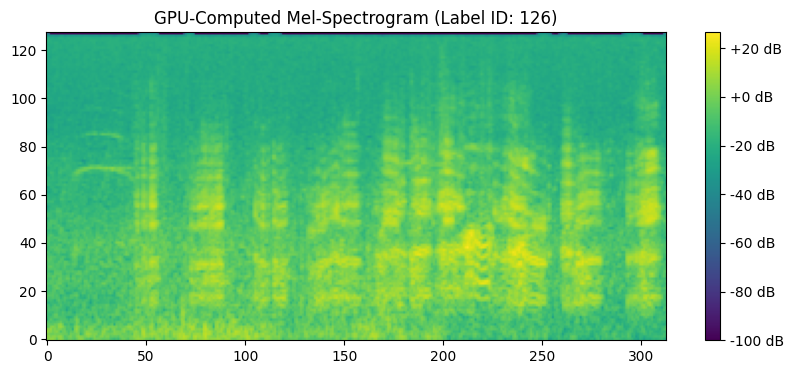

Error loading data/birdclef-2025/train_audio/yeofly1/XC254002.ogg: Failed to create AudioDecoder for data/birdclef-2025/train_audio/yeofly1/XC254002.ogg: SingleStreamDecoder, /__w/torchcodec/torchcodec/meta-pytorch/torchcodec/src/torchcodec/_core/SingleStreamDecoder.cpp:51, Could not open input file: data/birdclef-2025/train_audio/yeofly1/XC254002.ogg No such file or directory
Error loading data/birdclef-2025/train_audio/yeofly1/XC920619.ogg: Failed to create AudioDecoder for data/birdclef-2025/train_audio/yeofly1/XC920619.ogg: SingleStreamDecoder, /__w/torchcodec/torchcodec/meta-pytorch/torchcodec/src/torchcodec/_core/SingleStreamDecoder.cpp:51, Could not open input file: data/birdclef-2025/train_audio/yeofly1/XC920619.ogg No such file or directory


In [10]:
import torch
import torchaudio.transforms as T
from torch.utils.data import DataLoader
from src.data import BirdCLEFAudioDataset
import matplotlib.pyplot as plt

# Ensure GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Create Dataset and DataLoader
train_dataset = BirdCLEFAudioDataset(train_df, audio_dir='data/birdclef-2025/train_audio')
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)

# Define GPU-based MelSpectrogram transformations
mel_transform = T.MelSpectrogram(
    sample_rate=32000,
    n_fft=2048,
    hop_length=512,
    n_mels=128
).to(device)

amplitude_to_db = T.AmplitudeToDB().to(device)

# Fetch a batch and apply transformations on GPU
for waveforms, labels in train_loader:
    waveforms = waveforms.to(device)
    labels = labels.to(device)

    # 1. Convert waveforms to Mel-spectrograms on GPU
    mels = mel_transform(waveforms)

    # 2. Convert to Decibel scale on GPU
    mels_db = amplitude_to_db(mels)

    print(f"Waveform batch shape: {waveforms.shape}")
    print(f"Mel-spectrogram batch shape: {mels_db.shape}")

    # Plot the first item in the batch
    plt.figure(figsize=(10, 4))
    plt.imshow(mels_db[0, 0].cpu().numpy(), aspect='auto', origin='lower', cmap='viridis')
    plt.title(f"GPU-Computed Mel-Spectrogram (Label ID: {labels[0].item()})")
    plt.colorbar(format='%+2.0f dB')
    plt.show()
    break

--- Number of Background Birds per Recording ---
num_secondary_birds
1     27744
2       510
3       181
4        52
5        29
0        25
6         9
7         7
8         3
9         2
11        1
10        1
Name: count, dtype: int64


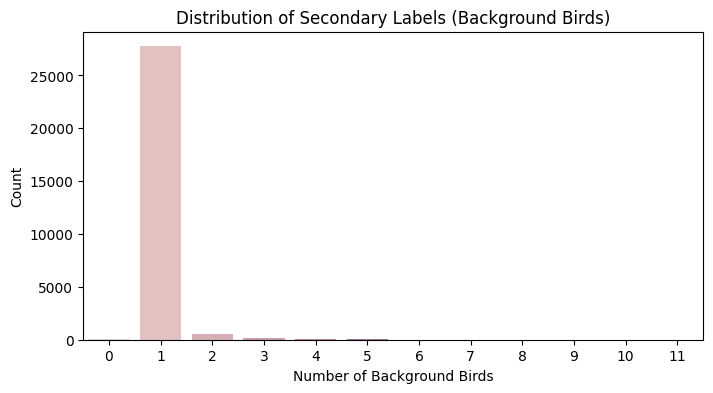


Highly noisy sample found in file: 126247/XC941297.ogg
Primary Bird: 126247
Background Birds: ['65448', '22976', '476538']


In [29]:
import ast
import matplotlib.pyplot as plt
import seaborn as sns

# Convert string representation of lists to actual Python lists
df['secondary_labels_list'] = df['secondary_labels'].apply(ast.literal_eval)
df['num_secondary_birds'] = df['secondary_labels_list'].apply(len)

print("--- Number of Background Birds per Recording ---")
print(df['num_secondary_birds'].value_counts())

# Visualize the distribution
plt.figure(figsize=(8, 4))
sns.countplot(data=df, hue='num_secondary_birds', x='num_secondary_birds', legend=False)
plt.title('Distribution of Secondary Labels (Background Birds)')
plt.xlabel('Number of Background Birds')
plt.ylabel('Count')
plt.show()

# Example of a highly noisy label
noisy_sample = df[df['num_secondary_birds'] > 2].iloc[0]
print(f"\nHighly noisy sample found in file: {noisy_sample['filename']}")
print(f"Primary Bird: {noisy_sample['primary_label']}")
print(f"Background Birds: {noisy_sample['secondary_labels_list']}")